## **Expiry-Day Liquidity Concentration in Indian Index Derivatives**

### **Notebook: 06: Expiry-Day Concentration (six indices)**

---

**Scope:** Monthly expiry-day turnover and share for NSE and BSE indices, and the turnover profile around true expiries.

---

### Pipeline sequence

1. **01_data_collection.ipynb** -- index OHLCV, F&O Bhavcopy archive (NOTE: the rule-based expiry calendar it builds is NOT used for inference)
2. **02_feature_engineering_and_fo_construction.ipynb** -- technical features (true-calendar expiry features) and the true-expiry index panel
3. **03_weekly_options_discontinuation_identification.ipynb** -- true expiry dates per index and a calendar audit
4. **04_primary_diff_in_diff_analysis.ipynb** -- corrected symbol-month DiD (turnover, expiry-day turnover, expiry-day share)
5. **05_robustness_checks.ipynb** -- placebo, window sensitivity, substitution range, participant mix, futures market quality
6. **06_expiry_volume_event_study.ipynb** -- expiry-day concentration for six NSE/BSE indices
7. **07_walk_forward_predictability.ipynb** -- secondary: leakage-free predictability test on the true calendar (null)
8. **08_interrupted_time_series.ipynb** -- secondary: settlement-weekday ITS plus clean weekday-only contrasts (null)
9. **09_figures.ipynb** -- displays the corrected figures
10. **10_option_microstructure_and_placebo.ipynb** -- option-level outcomes, stock-F&O placebo, dose-response

**Current location:** **06_expiry_volume_event_study.ipynb** <- *you are here*


In [1]:
import sys
from pathlib import Path

project_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

import pandas as pd
import json
from src import config

pd.set_option('display.max_columns', 20)
print('Project root:', project_dir)

Project root: E:\Research-IPR\Research_BN_N50\banknifty-expiry-volatility-ml


In [2]:
m = pd.read_parquet(config.INTERIM_DATA_DIR / 'monthly_expiry_panel_all.parquet')
m = m[(m.exp_day > 0) & (m.ym >= pd.Period('2023-06')) & (m.ym != pd.Period('2024-11'))].copy()
m['period'] = (m.ym >= pd.Period('2024-12')).map({False: 'pre', True: 'post'})
m.groupby(['Symbol', 'period'])[['tot', 'exp_day', 'share', 'nexp']].mean()

tot       exp_day     share      nexp
Symbol     period                                                
BANKEX     post    2.138980e+13  1.976151e+13  0.902625  1.000000
           pre     3.355645e+14  8.031561e+13  0.212549  4.294118
BANKNIFTY  post    3.366146e+14  1.480460e+14  0.456715  1.000000
           pre     3.106011e+15  4.090936e+14  0.131444  4.411765
FINNIFTY   post    2.024009e+13  1.421090e+13  0.663334  1.000000
           pre     1.250059e+15  2.429734e+14  0.194511  4.352941
MIDCPNIFTY post    3.257838e+13  1.677201e+13  0.479272  1.000000
           pre     4.140853e+14  8.486039e+13  0.209171  4.294118
NIFTY      post    4.368399e+15  4.771817e+14  0.110784  4.260870
           pre     2.473395e+15  3.125390e+14  0.125603  4.411765
SENSEX     post    3.575373e+15  6.154609e+14  0.174251  4.173913
           pre     1.093393e+15  2.256078e+14  0.227695  4.352941

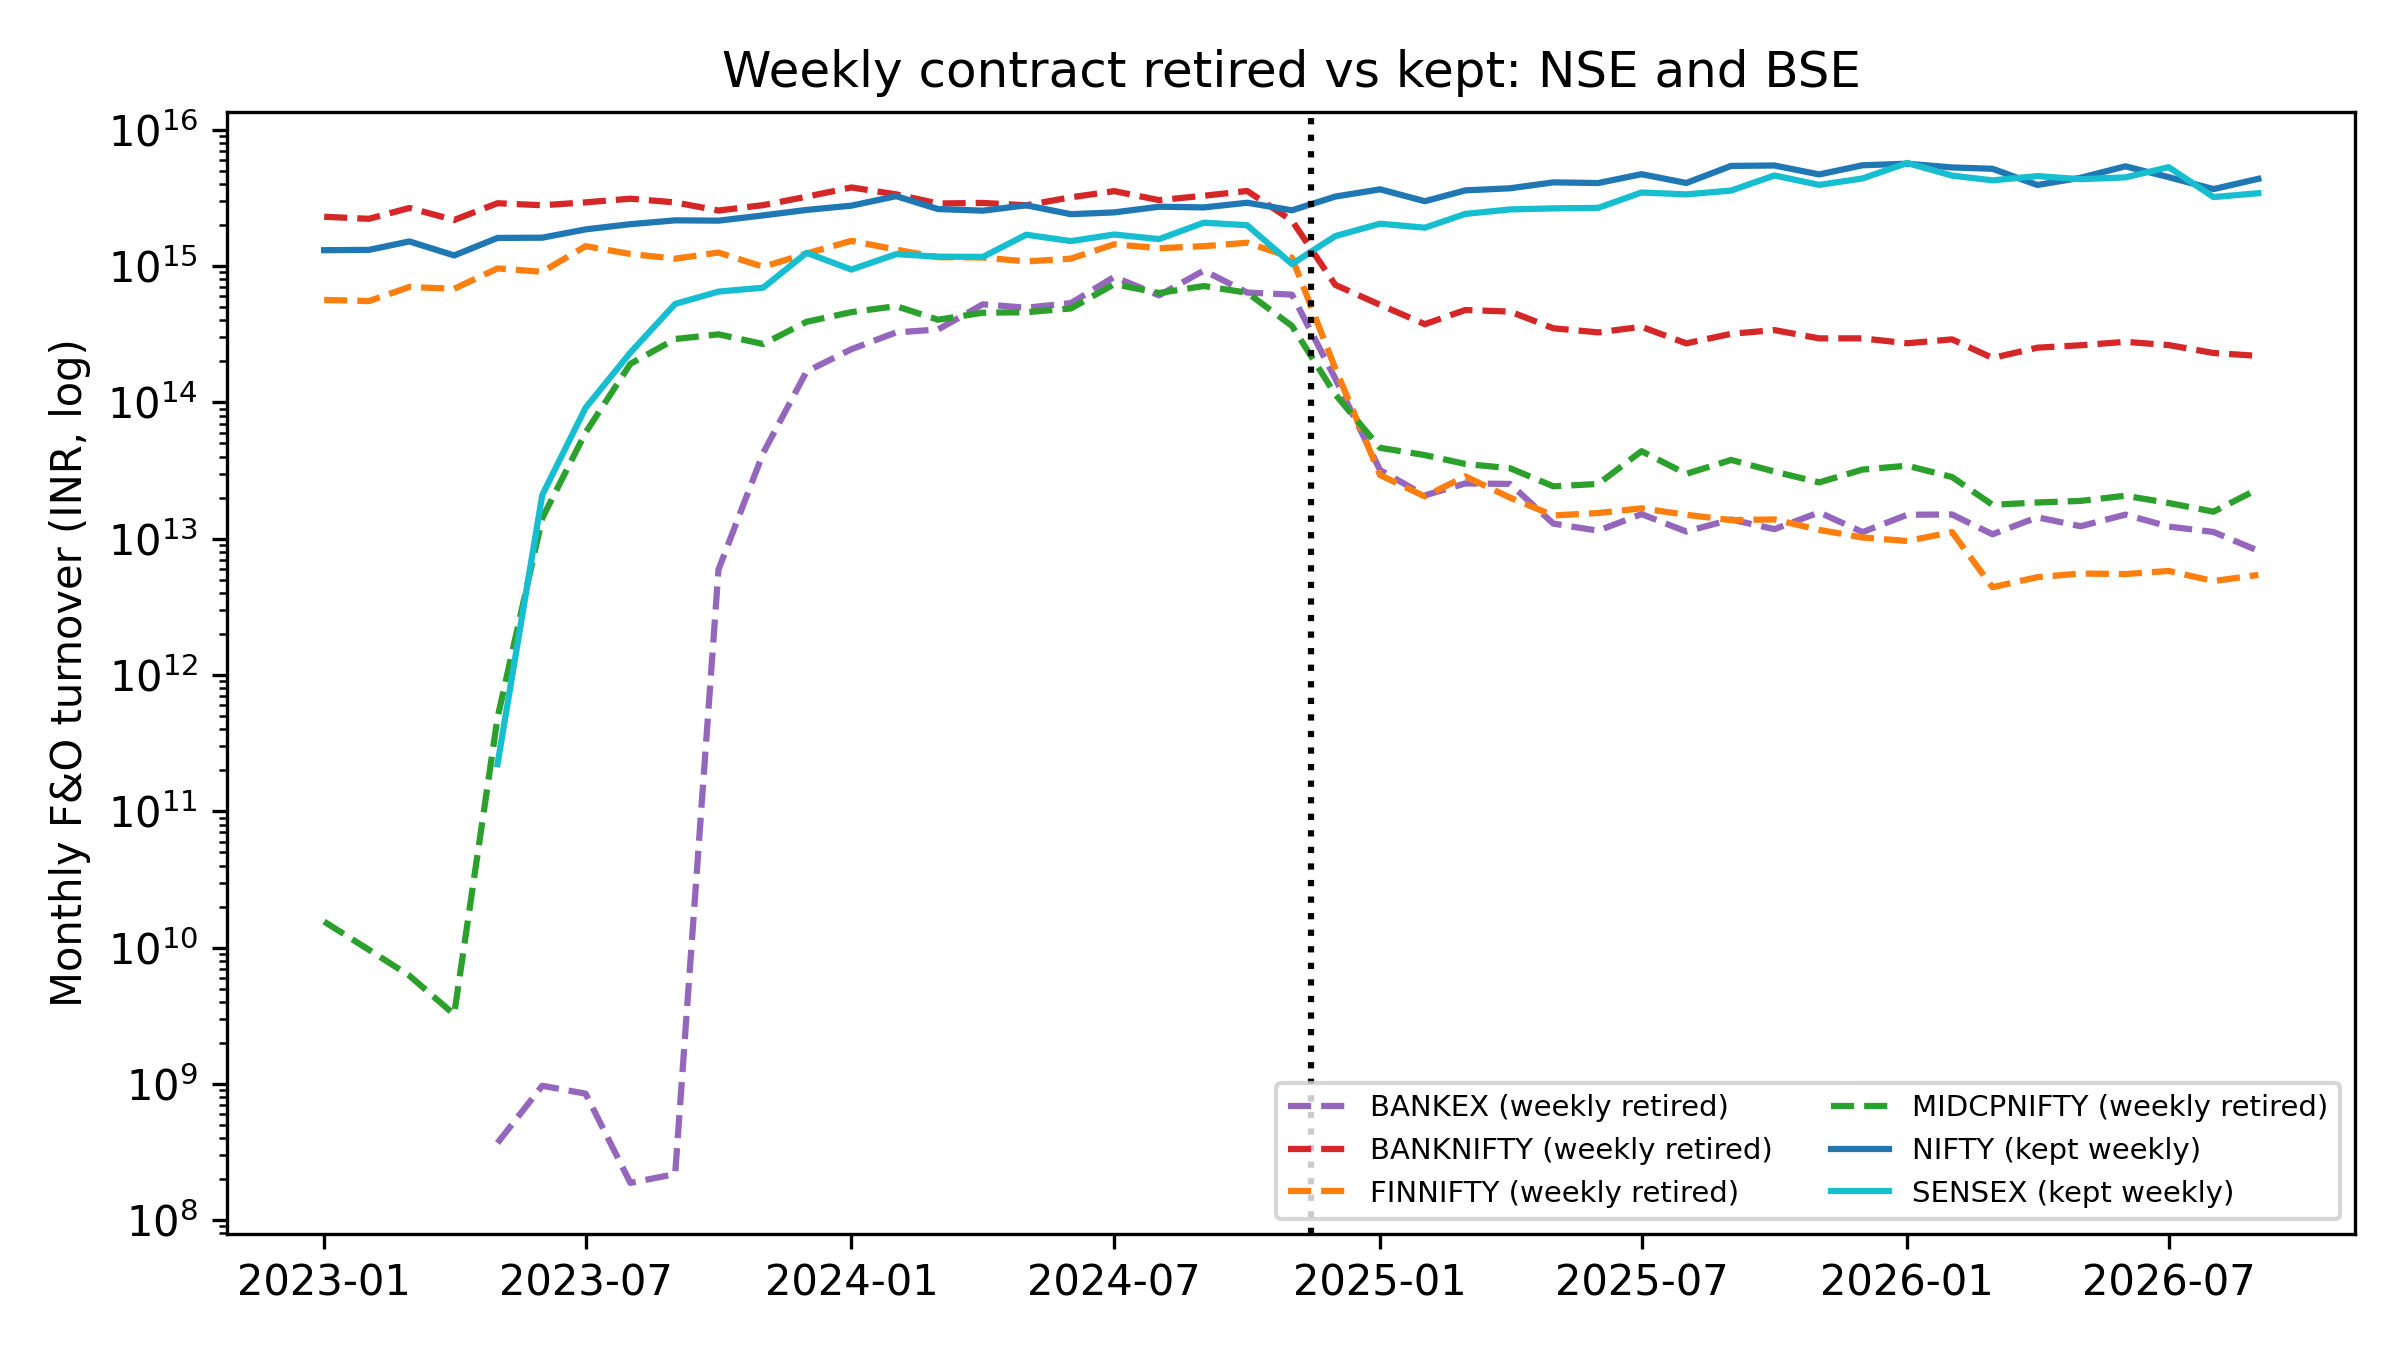

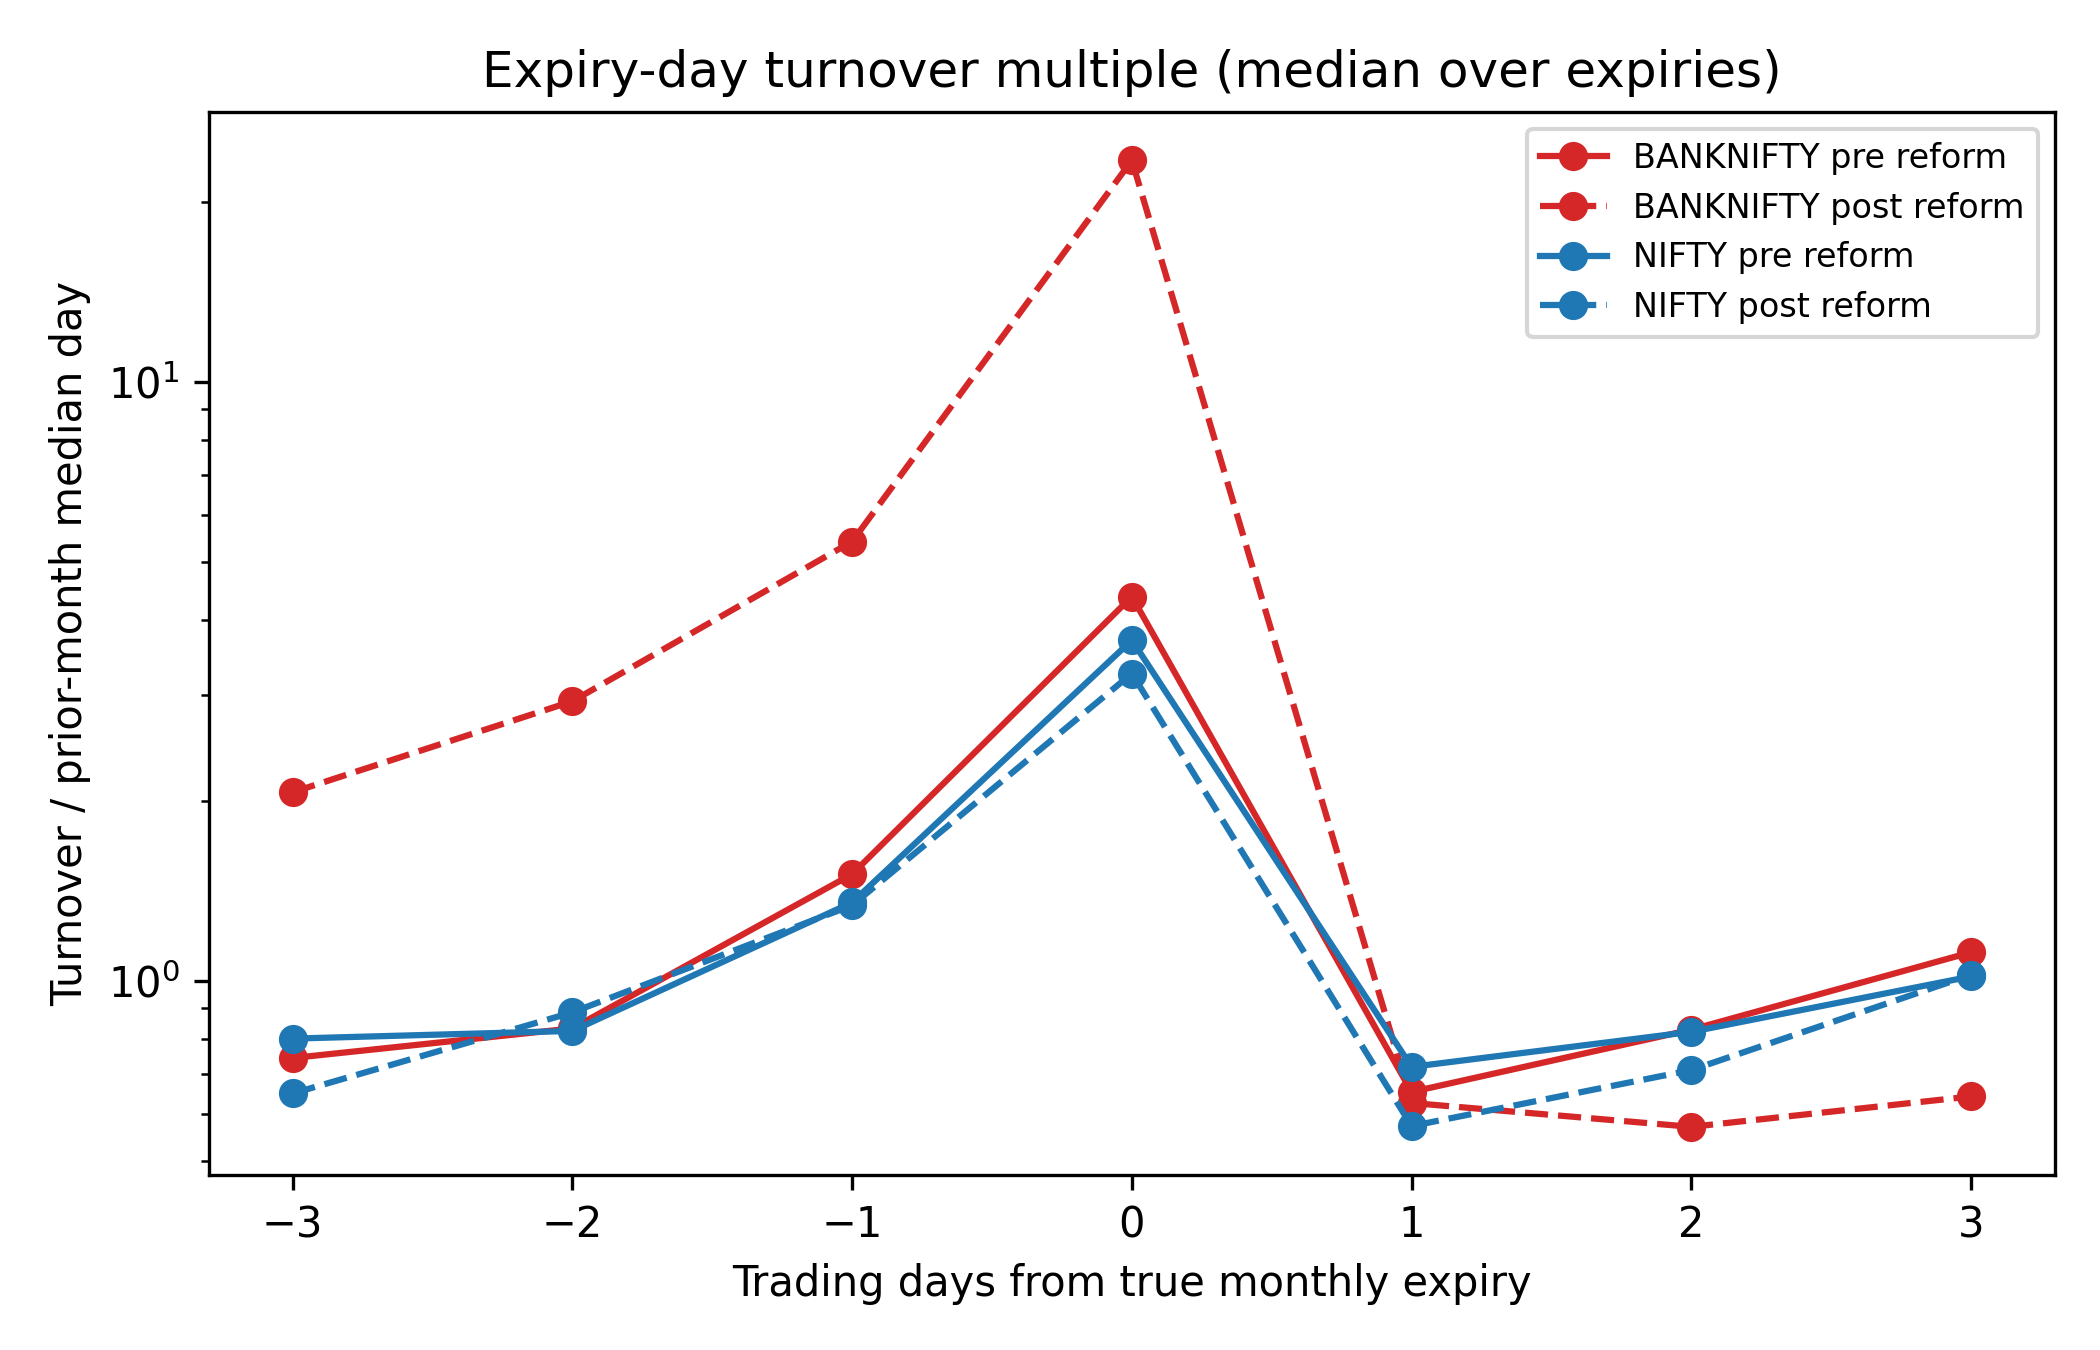

In [3]:
from IPython.display import Image, display
for f in ['fig5_six_index_turnover.png', 'fig4_expiry_profile_true.png']:
    display(Image(filename=str(config.FIGURES_DIR / f)))